# Music taste and political ideology: replicating Myers (2019) with Machine 2

**Paper:** Myers, C. (2019). *The songs of my people: appraisal differences of popular music as a function of
ideology.* NYU undergraduate honors thesis, advisor P. Wallisch (PDF in `references/`).

**What the paper did**
1. 576 participants rated music clips from 260 songs on a 1–7 liking scale (each person heard a random subset) and
   reported their ideology. With few conservatives, people were split into **liberal (n = 346)** vs.
   **non-liberal (n = 230:** conservative, moderate, independent, other).
2. **Exclusions:** 15 with missing data, 13 without the demographic survey, and 49 "click-through" participants whose
   ratings on odd- vs. even-numbered presentations correlated below 0.4.
3. **Genre level (Figs 1–4):** self-reported listening and in-lab liking / familiarity per genre, liberal / moderate /
   conservative.
4. **Song level (Fig 5):** for every song, mean rating of liberals − mean rating of non-liberals ("mean diff").
5. **Reclassification (Fig 6):** each person's *Musical Ideology Index* = dot product of their ratings with the
   vector of song mean diffs. Sweeping a cutoff on the index, the best cutoff classified **71.5 %** of people
   correctly (always guessing "liberal" gives 60.1 %). No p-values and no held-out test were reported.

The index is a linear classifier whose weights are the two groups' mean differences (a nearest-centroid / diagonal
discriminant rule). In the paper the weights **and** the cutoff were estimated on the same people who were then
classified, so 71.5 % is an in-sample number. Section 4 reproduces it exactly that way; section 5 measures how much of
it holds up on held-out participants and against shuffled labels.

**Mapping to Machine 2**

| | Paper | Machine 2 (this notebook) |
|---|---|---|
| Songs | 260; each person rated a random subset | all **320 core clips**; every person rated all of them |
| Rating | 1–7 liking | 1–7 liking (same scale) |
| Ideology answers | liberal, moderate, conservative, independent, other | Liberal, Progressive, Socialist, Moderate, Conservative, Libertarian, Alt-Right, I don't care |
| "Liberal" | liberal | Liberal + Progressive + Socialist (`LIBERAL`) |
| "Non-liberal" | everyone else | everyone else, including "I don't care" |
| Liberal / moderate / conservative (Figs 1–4) | as answered | Liberal+Progressive+Socialist / Moderate / Conservative+Libertarian+Alt-Right |
| Click-through check | same songs on odd vs. even presentations, r < 0.4 | songs never repeat, so odd vs. even **trials** are compared through their 9 genre means, r < 0.4 |
| Familiarity | recognise song / artist / both | 1–5 scale |
| Self-reported listening | genres listened to | "Which genres do you like to listen to?" (the paper's 8 genres) |

The grouping is the main judgment call; section 6 reruns the reclassification with three other groupings.

In [1]:
import sqlite3, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
warnings.filterwarnings('ignore')

conn = sqlite3.connect("../data/machine2_new_aug.db")
XLS = "../data/Music preference prescreening survey.xlsx"
PAPER_CSV = "../references/myers2019_fig5_song_differences.csv"   # the paper's Fig 5 values, transcribed

MIN_RATED = 250           # rated >= 250 of the 320 core clips (paper: drop missing / incomplete data)
MIN_CONSISTENCY = 0.4     # the paper's click-through threshold
MIDPOINT = 4              # "Indifferent"; ratings are centred here for the ideology index (an unrated clip adds 0)
LIBERAL = ['Liberal', 'Progressive', 'Socialist']
THREE = {'Liberal': 'L', 'Progressive': 'L', 'Socialist': 'L', 'Moderate': 'M',
         'Conservative': 'C', 'Libertarian': 'C', 'Alt-Right': 'C'}            # "I don't care" is not in Figs 1-4
N_PERM = 1000             # label permutations for every null distribution
CV_SPLITS, CV_REPEATS = 5, 20
SEED = 42

GENRES = {1: 'Classical', 2: 'Country', 3: 'Electronic', 4: 'Jazz', 5: 'Pop', 6: 'Rap', 7: 'Rock', 8: 'R&B/Soul',
          9: 'World'}
PAPER_GENRES = ['Classical', 'Country', 'Electronic', 'Jazz', 'Pop', 'Rap', 'Rock', 'R&B/Soul']

BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, INK2, GRID, MUTED = '#21201c', '#52514e', '#e4e3df', '#b9b8b3'
GROUP_COLORS = {'L': BLUE, 'M': '#9a9994', 'C': ORANGE}
THREE_NAMES = {'L': 'Liberal / progressive / socialist', 'M': 'Moderate', 'C': 'Conservative / libertarian / alt-right'}
GENRE_COLORS = {'Classical': '#8c6bb1', 'Country': '#eda100', 'Electronic': AQUA, 'Jazz': '#4fb3d9',
                'Pop': '#e87ba4', 'Rap': '#d64541', 'Rock': INK2, 'R&B/Soul': '#a0522d', 'World': '#7a9a01'}


def style(a, axis='y'):
    a.spines[['top', 'right']].set_visible(False)
    a.grid(axis=axis, color=GRID, lw=0.6); a.set_axisbelow(True)


def short(s, n=18):
    s = str(s); return s if len(s) <= n else s[:n - 1] + '…'


def p_perm(null, obs):
    return (1 + np.sum(np.asarray(null) >= obs)) / (1 + len(null))

## 1. Data
### 1.1 Ratings and familiarity of the 320 core clips
A song is identified by `instanceId`. The 320 clips presented exactly once to every participant are used; clip 1000
(the exposure clip, played ~12× per person) is excluded everywhere.

In [2]:
n_part = pd.read_sql_query("SELECT COUNT(DISTINCT participantId) n FROM music", conn).n[0]
core = pd.read_sql_query(f'''
    SELECT instanceId FROM music GROUP BY instanceId
    HAVING COUNT(DISTINCT participantId) = {n_part} AND COUNT(*) = {n_part}
''', conn).instanceId.sort_values().tolist()
music = pd.read_sql_query("""SELECT participantId, trialNumber, instanceId, rating, familiarity
                             FROM music WHERE instanceId != 1000""", conn)
meta = pd.read_sql_query("SELECT MusicId, Title, Artist, Year, GenreId FROM music_meta", conn).set_index('MusicId')
meta['genre'] = meta.GenreId.map(GENRES)

cm = music[music.instanceId.isin(core)]
R_all = cm.pivot(index='participantId', columns='instanceId', values='rating')        # errors on any duplicate
F_all = cm.pivot(index='participantId', columns='instanceId', values='familiarity')
song_genre = meta.loc[core, 'genre']
print(f"{n_part} participants in the DB, {len(core)} core clips")
song_genre.value_counts().reindex(GENRES.values()).rename('core clips').to_frame().T

1072 participants in the DB, 320 core clips


genre,Classical,Country,Electronic,Jazz,Pop,Rap,Rock,R&B/Soul,World
core clips,21,22,22,18,63,32,67,30,45


### 1.2 Click-through check (paper: odd/even consistency < 0.4)
The paper correlated each person's ratings of the same songs on odd- vs. even-numbered presentations. Machine 2 never
repeats a song, so each person's rated trials (core and non-core clips) are split into odd and even positions, the mean
rating of each of the 9 genres is computed in each half, and the two sets of genre means are correlated. Someone who
clicks at random has no stable genre preferences, so their r is near 0.

In [3]:
t = music[music.rating.notna()].join(meta.GenreId, on='instanceId')
t = t[t.GenreId.between(1, 9)].sort_values(['participantId', 'trialNumber'])
t['half'] = np.where(t.groupby('participantId').cumcount() % 2 == 0, 'odd', 'even')
gm = t.pivot_table(index=['participantId', 'GenreId'], columns='half', values='rating', aggfunc='mean').dropna()
consistency = gm.groupby(level='participantId').apply(lambda g: g.odd.corr(g.even) if len(g) >= 5 else np.nan)
consistency.describe().round(3).to_frame('odd/even genre-mean r').T

,count,mean,std,min,25%,50%,75%,max
odd/even genre-mean r,1037.0,0.818,0.172,-0.478,0.78,0.868,0.92,0.996


### 1.3 Prescreen survey, joined on the 4-character code
Codes that appear more than once in the Excel, or 4-character prefixes shared by several DB participants, are
ambiguous and dropped.

In [4]:
raw = pd.read_excel(XLS, header=None).astype(object)
survey = raw.iloc[2:].reset_index(drop=True).copy()
survey['code'] = survey[9].map(lambda s: str(s).strip().lower())
survey = survey[~survey.code.duplicated(keep=False)].set_index('code')

prefix = pd.Series(R_all.index.str[:4].str.lower(), index=R_all.index)
prefix = prefix[~prefix.duplicated(keep=False) & prefix.isin(survey.index)]
S = survey.loc[prefix.values].set_index(prefix.index)
ideology = S[108].map(lambda v: v.strip() if isinstance(v, str) and v.strip() else np.nan)

# "Which genres do you like to listen to? (Select all that apply)": columns 57-84, the paper's 8 genres used
LISTEN_COLS = {'Classical': 59, 'Country': 60, 'Electronic': 63, 'Jazz': 69, 'Pop': 73, 'Rap': 75, 'R&B/Soul': 76,
               'Rock': 79}
assert [raw.iloc[1, c] for c in LISTEN_COLS.values()] == ['Classical', 'Country', 'Electronic', 'Jazz', 'Pop',
                                                         'Rap/Hiphop', 'R&B/Soul', 'Rock']
answered = S[list(range(57, 85))].notna().any(axis=1)          # ticked at least one genre
listen = pd.DataFrame({g: S[c].notna().astype(float) for g, c in LISTEN_COLS.items()})
listen.loc[~answered, :] = np.nan
print(f"{len(S)} DB participants matched 1:1 to the survey")

827 DB participants matched 1:1 to the survey


### 1.4 Analysis sample and groups
Paper: 653 recruited → 15 missing data → 13 no demographics → 49 click-through → **576**.

In [5]:
rated = R_all.notna().sum(axis=1)
steps = [('in the DB music table', R_all.index),
         ('matched 1:1 to the survey', S.index)]
steps.append((f'rated >= {MIN_RATED} of the 320 core clips', S.index[rated.reindex(S.index).to_numpy() >= MIN_RATED]))
steps.append(('answered the ideology question', steps[-1][1][ideology.reindex(steps[-1][1]).notna().to_numpy()]))
passes = consistency.reindex(steps[-1][1]).to_numpy() >= MIN_CONSISTENCY            # NaN counts as failing
steps.append((f'odd/even consistency >= {MIN_CONSISTENCY}  → analysis sample', steps[-1][1][passes]))
flow = pd.DataFrame([(s, len(i)) for s, i in steps], columns=['step', 'participants'])
flow['dropped'] = (-flow.participants.diff()).fillna(0).astype(int)
sample = steps[-1][1]

R, F = R_all.loc[sample], F_all.loc[sample]
ideo = ideology.loc[sample]
y = ideo.isin(LIBERAL).astype(int)                       # 1 = liberal, 0 = non-liberal
three = ideo.map(THREE)                                  # L / M / C; NaN for "I don't care"
display(flow)
groups = pd.DataFrame({'answer': ideo, 'paper group': y.map({1: 'liberal', 0: 'non-liberal'}),
                       'Figs 1-4 group': three.map(THREE_NAMES)})
display(groups.value_counts(dropna=False).rename('n').reset_index())
print(f"liberal {y.sum()} ({y.mean():.1%}) vs. non-liberal {(1 - y).sum()}   |   paper: 346 (60.1%) vs. 230")

,step,participants,dropped
0,in the DB music table,1072,0
1,matched 1:1 to the survey,827,245
2,rated >= 250 of the 320 core clips,777,50
3,answered the ideology question,769,8
4,odd/even consistency >= 0.4 → analysis sample,752,17


,answer,paper group,Figs 1-4 group,n
0,Liberal,liberal,Liberal / progressive / socialist,333
1,I don't care,non-liberal,NaN,129
2,Moderate,non-liberal,Moderate,102
3,Progressive,liberal,Liberal / progressive / socialist,86
4,Socialist,liberal,Liberal / progressive / socialist,61
5,Conservative,non-liberal,Conservative / libertarian / alt-right,25
6,Libertarian,non-liberal,Conservative / libertarian / alt-right,11
7,Alt-Right,non-liberal,Conservative / libertarian / alt-right,5


liberal 480 (63.8%) vs. non-liberal 272   |   paper: 346 (60.1%) vs. 230


## 2. Genre-level differences (paper Figs 1–4)
Liberal / moderate / conservative as in the paper ("I don't care" is left out here). Bars are means ± 1 SEM.
* **a** how many of the paper's 8 genres a person says they listen to (Fig 1)
* **b** share who say they listen to each genre (Fig 2)
* **c, d** mean in-lab liking and familiarity of each genre's core clips (Figs 3–4; Machine 2 also has World music).
  In the paper, Fig 4 is an exact copy of Fig 3, so familiarity has no published counterpart.

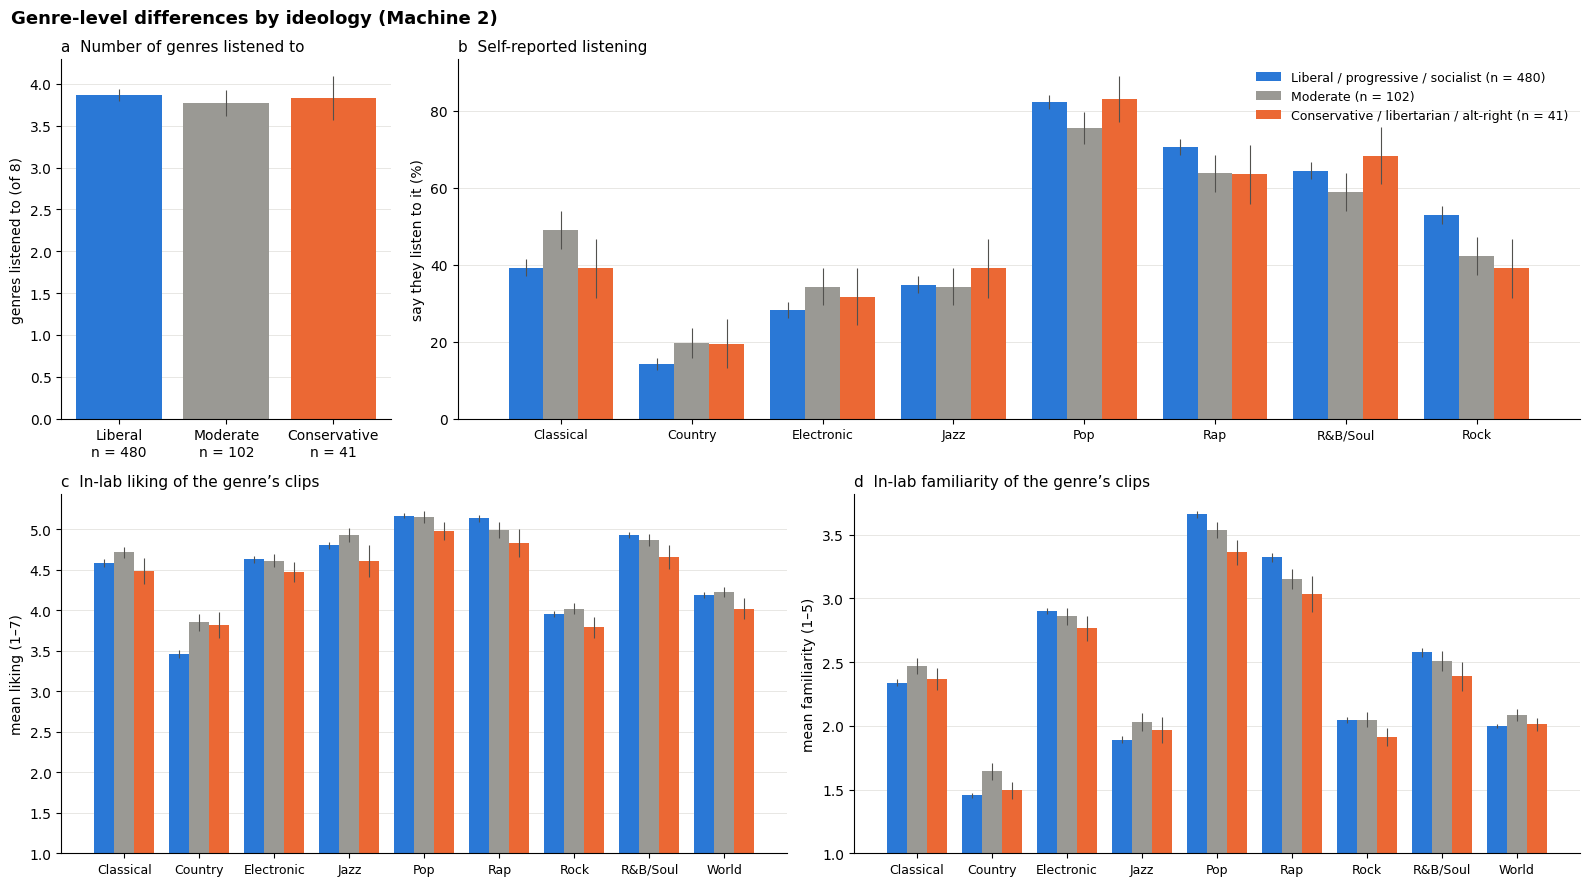

In [6]:
appraisal = R.T.groupby(song_genre).mean().T[list(GENRES.values())]       # person × genre mean liking
familiarity = F.T.groupby(song_genre).mean().T[list(GENRES.values())]
lst = listen.loc[sample].dropna()
ORDER3 = ['L', 'M', 'C']


def by_group(df, g):
    g = g.reindex(df.index).dropna()
    d = df.loc[g.index].groupby(g)
    return d.mean().reindex(ORDER3), d.sem().reindex(ORDER3), d.size().reindex(ORDER3)


def grouped_bars(a, df, ylabel, title, scale=1.0, bottom=0):
    m, s, n = by_group(df, three)
    x, w = np.arange(m.shape[1]), 0.8 / len(ORDER3)
    for i, k in enumerate(ORDER3):
        a.bar(x + (i - 1) * w, scale * m.loc[k] - bottom, w, bottom=bottom, yerr=scale * s.loc[k], color=GROUP_COLORS[k],
              error_kw=dict(lw=0.8, ecolor=INK2), label=f"{THREE_NAMES[k]} (n = {n[k]})")
    a.set_xticks(x); a.set_xticklabels(m.columns, fontsize=9)
    a.set_ylabel(ylabel); a.set_title(title, loc='left', fontsize=11); style(a)


fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 4)
ax_a, ax_b = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1:])
ax_c, ax_d = fig.add_subplot(gs[1, :2]), fig.add_subplot(gs[1, 2:])
m, s, n = by_group(lst.sum(axis=1), three)
ax_a.bar(range(3), m, yerr=s, color=[GROUP_COLORS[k] for k in ORDER3], error_kw=dict(lw=0.8, ecolor=INK2))
ax_a.set_xticks(range(3))
ax_a.set_xticklabels([f"{lab}\nn = {n[k]}" for k, lab in zip(ORDER3, ['Liberal', 'Moderate', 'Conservative'])])
ax_a.set_ylabel('genres listened to (of 8)'); ax_a.set_title('a  Number of genres listened to', loc='left', fontsize=11)
style(ax_a)
grouped_bars(ax_b, lst, 'say they listen to it (%)', 'b  Self-reported listening', scale=100)
grouped_bars(ax_c, appraisal, 'mean liking (1–7)', 'c  In-lab liking of the genre’s clips', bottom=1)
grouped_bars(ax_d, familiarity, 'mean familiarity (1–5)', 'd  In-lab familiarity of the genre’s clips', bottom=1)
ax_b.legend(frameon=False, fontsize=9, loc='upper right')
fig.suptitle('Genre-level differences by ideology (Machine 2)', x=0.01, ha='left', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

### 2.1 Does saying you listen to a genre go with liking its clips?
The paper reported that self-reported listening was **not** correlated with in-lab appraisal. Below, point-biserial r
between "listens to the genre" (yes / no) and the person's mean liking / familiarity of that genre's clips, all
participants who answered the question.

In [7]:
def pb(x, z):
    d = pd.concat([x, z], axis=1).dropna()
    return st.pointbiserialr(d.iloc[:, 0], d.iloc[:, 1])


rows = []
for g in PAPER_GENRES:
    (r_a, p_a), (r_f, p_f) = pb(lst[g], appraisal[g]), pb(lst[g], familiarity[g])
    rows.append(dict(genre=g, share_listen=lst[g].mean(), r_liking=r_a, p_liking=p_a,
                     r_familiarity=r_f, p_familiarity=p_f))
pd.DataFrame(rows).set_index('genre').round(3)

,share_listen,r_liking,p_liking,r_familiarity,p_familiarity
genre,,,,,
Classical,0.401,0.465,0.0,0.303,0.000
Country,0.162,0.372,0.0,0.120,0.001
Electronic,0.300,0.262,0.0,0.124,0.001
Jazz,0.341,0.474,0.0,0.304,0.000
Pop,0.812,0.231,0.0,0.081,0.027
Rap,0.679,0.451,0.0,0.352,0.000
Rock,0.467,0.446,0.0,0.348,0.000
R&B/Soul,0.622,0.287,0.0,0.188,0.000


## 3. Song-level differences (paper Fig 5), all 320 core clips
`mean_diff` = mean rating of liberals − mean rating of non-liberals (positive = liberals like the song more).
The paper reported mean differences only. Here each song also gets a Welch t-test (BH-FDR over the 320 songs), and a
label-permutation null of the **largest** |mean diff| gives a family-wise 5 % threshold: with 320 songs some sizeable
differences appear by chance alone.

The next cell also defines the reclassification machinery used in sections 4–6.

songs with FDR q < .05: 143 of 320  |  |mean diff| above the family-wise threshold (0.46): 51
liberal-leaning: 222, non-liberal-leaning: 98; |mean diff| median 0.23, max 0.82


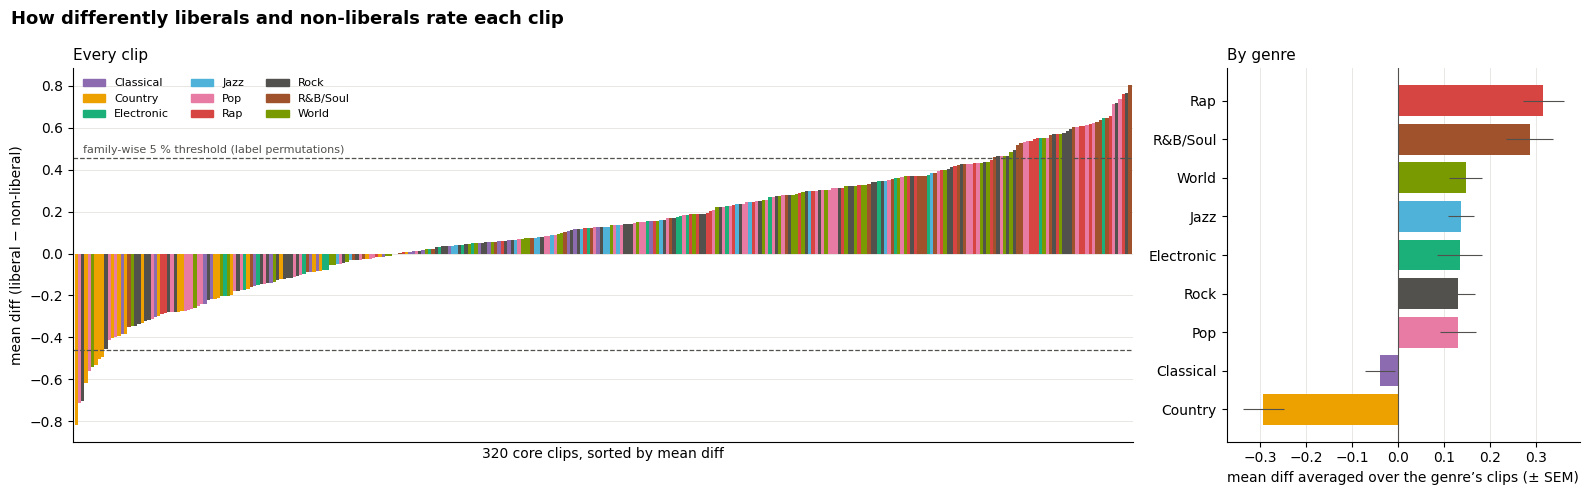

In [8]:
def arrays(R):
    """Ratings with missing values as 0, the rated-mask, and ratings centred at MIDPOINT (missing -> 0)."""
    Rm = R.to_numpy(float)
    return np.nan_to_num(Rm), (~np.isnan(Rm)).astype(float), np.where(np.isnan(Rm), 0.0, Rm - MIDPOINT)


def mean_diff(Rf, M, y):
    """Per clip: mean rating of liberals (y = 1) minus mean rating of non-liberals, missing ratings skipped."""
    lib = y == 1
    return Rf[lib].sum(0) / M[lib].sum(0) - Rf[~lib].sum(0) / M[~lib].sum(0)


def accuracy_by_cutoff(score, y):
    """Accuracy of 'liberal if score > cutoff' at every cutoff between consecutive sorted scores (and both ends)."""
    o = np.argsort(score); s, ys = score[o], y[o]
    correct = np.r_[0, np.cumsum(1 - ys)] + ys.sum() - np.r_[0, np.cumsum(ys)]
    return np.r_[s[0] - 1, (s[:-1] + s[1:]) / 2, s[-1] + 1], correct / len(y)


def best_cutoff(score, y):
    cuts, acc = accuracy_by_cutoff(score, y)
    k = acc.argmax()
    return cuts[k], acc[k]


def reclassify_in_sample(Rf, M, U, y):
    """The paper's method: mean diffs, index and cutoff all from the people being classified."""
    md = mean_diff(Rf, M, y)
    index = U @ md
    cut, acc = best_cutoff(index, y)
    return md, index, cut, acc


def loo_index(Rf, M, U, y):
    """Each person's index computed from mean diffs that leave that person out."""
    lib = y == 1
    sL, nL, sN, nN = Rf[lib].sum(0), M[lib].sum(0), Rf[~lib].sum(0), M[~lib].sum(0)
    out = np.empty(len(y))
    out[lib] = (U[lib] * ((sL - Rf[lib]) / (nL - M[lib]) - sN / nN)).sum(1)
    out[~lib] = (U[~lib] * (sL / nL - (sN - Rf[~lib]) / (nN - M[~lib]))).sum(1)
    return out


def cv_reclassify(Rf, M, U, y, seed):
    """Held-out version: mean diffs and cutoff come from the training folds only. The cutoff is chosen on the
    training people's leave-one-out indices, because their in-sample indices are inflated by their own ratings."""
    score, pred = np.empty(len(y)), np.empty(len(y), dtype=int)
    for tr, te in StratifiedKFold(CV_SPLITS, shuffle=True, random_state=seed).split(U, y):
        cut, _ = best_cutoff(loo_index(Rf[tr], M[tr], U[tr], y[tr]), y[tr])
        score[te] = U[te] @ mean_diff(Rf[tr], M[tr], y[tr])
        pred[te] = score[te] > cut
    return score, pred


def make_perms(y, seed=SEED, n=N_PERM):
    rng = np.random.default_rng(seed)
    return [rng.permutation(y) for _ in range(n)]


Rf, M, U = arrays(R)
yv = y.to_numpy()
PERMS = make_perms(yv)

lib, non = R[y == 1], R[y == 0]
t_stat, p_val = st.ttest_ind(lib, non, equal_var=False, nan_policy='omit')
songs = meta.loc[core, ['Title', 'Artist', 'Year', 'genre']].assign(
    mean_liberal=lib.mean(), mean_nonliberal=non.mean(), mean_diff=mean_diff(Rf, M, yv),
    t=np.asarray(t_stat), p=np.asarray(p_val))
songs['q_fdr'] = st.false_discovery_control(songs.p)
null_max_md = np.array([np.abs(mean_diff(Rf, M, yp)).max() for yp in PERMS])
FW = np.quantile(null_max_md, 0.95)
print(f"songs with FDR q < .05: {(songs.q_fdr < .05).sum()} of {len(songs)}  |  "
      f"|mean diff| above the family-wise threshold ({FW:.2f}): {(songs.mean_diff.abs() > FW).sum()}")
print(f"liberal-leaning: {(songs.mean_diff > 0).sum()}, non-liberal-leaning: {(songs.mean_diff < 0).sum()}; "
      f"|mean diff| median {songs.mean_diff.abs().median():.2f}, max {songs.mean_diff.abs().max():.2f}")

s_sorted = songs.sort_values('mean_diff')
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw=dict(width_ratios=[3, 1]))
a1.bar(np.arange(len(s_sorted)), s_sorted.mean_diff, width=1.0, color=s_sorted.genre.map(GENRE_COLORS))
for v in (FW, -FW):
    a1.axhline(v, ls='--', lw=0.9, color=INK2)
a1.text(2, FW + 0.02, 'family-wise 5 % threshold (label permutations)', fontsize=8, color=INK2)
a1.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in GENRE_COLORS.values()], GENRE_COLORS.keys(),
          frameon=False, fontsize=8, ncol=3, loc='upper left')
a1.set_xlim(-1, len(s_sorted)); a1.set_xticks([])
a1.set_xlabel('320 core clips, sorted by mean diff'); a1.set_ylabel('mean diff (liberal − non-liberal)')
a1.set_title('Every clip', loc='left', fontsize=11); style(a1)
by_genre = songs.groupby('genre').mean_diff.agg(['mean', 'sem']).sort_values('mean')
a2.barh(by_genre.index, by_genre['mean'], xerr=by_genre['sem'], color=[GENRE_COLORS[g] for g in by_genre.index],
        error_kw=dict(lw=0.8, ecolor=INK2))
a2.axvline(0, color=INK2, lw=0.8)
a2.set_xlabel('mean diff averaged over the genre’s clips (± SEM)')
a2.set_title('By genre', loc='left', fontsize=11); style(a2, 'x')
fig.suptitle('How differently liberals and non-liberals rate each clip', x=0.01, ha='left', fontsize=13,
             fontweight='bold')
plt.tight_layout(); plt.show()

The 30 most polarizing clips (as in paper Fig 5a): share of each rating, liberal vs. non-liberal; the frame colour is
the genre.

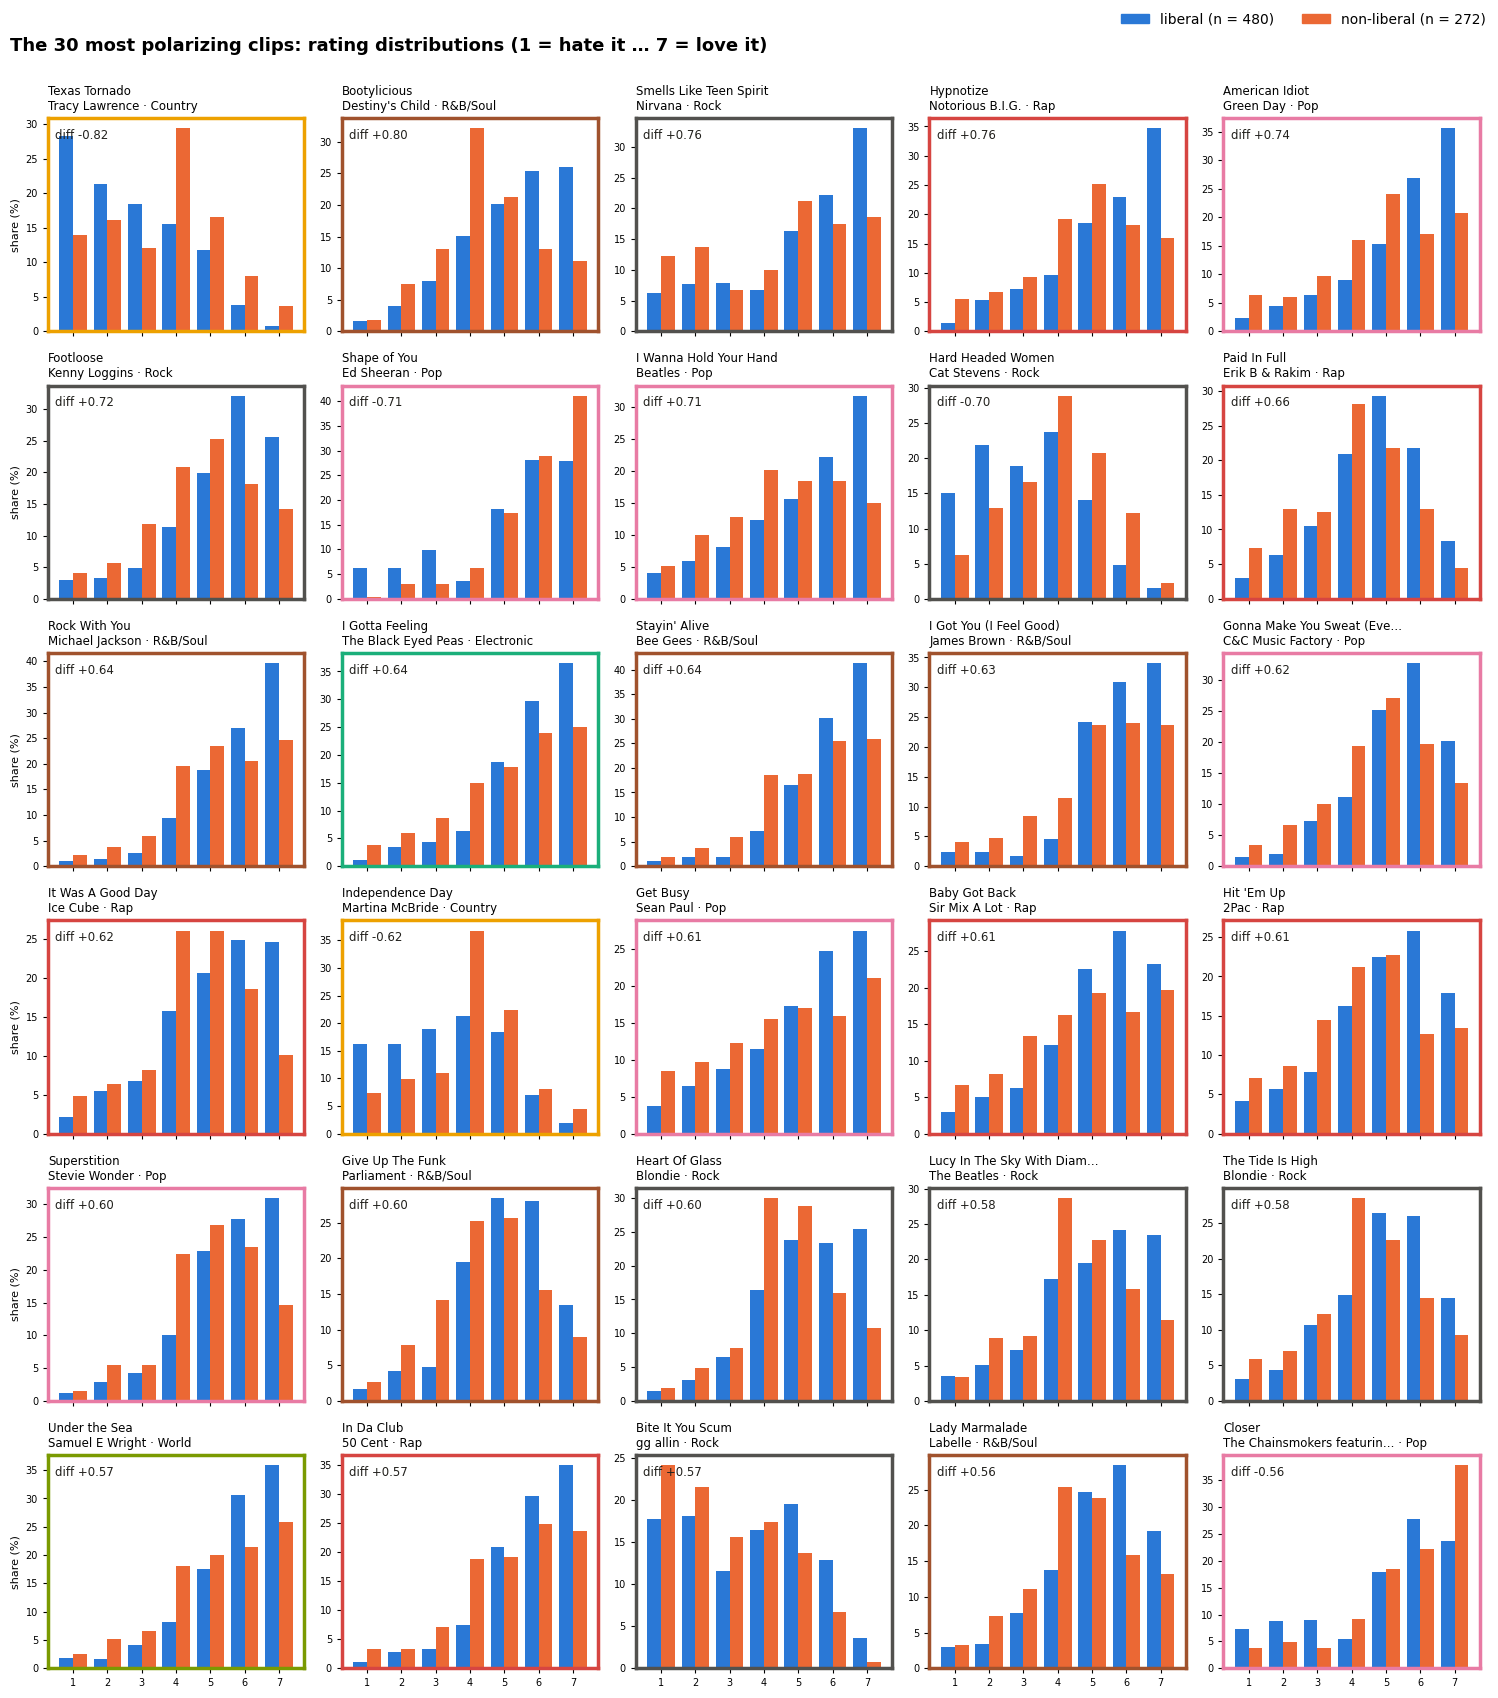

Title  \
                           MusicId                                         
liked more by liberals     71                               Bootylicious   
                           28                    Smells Like Teen Spirit   
                           73                                  Hypnotize   
                           20                             American Idiot   
                           86                                  Footloose   
                           242                    I Wanna Hold Your Hand   
                           252                              Paid In Full   
                           277                             Rock With You   
                           142                           I Gotta Feeling   
                           276                             Stayin' Alive   
liked more by non-liberals 46                              Texas Tornado   
                           103                              Shape of You   
                           171                         Hard Headed Women   
                           9                            Independence Day   
                           106                                    Closer   
                           289                                   Arirang   
                           219                     A Little Bit Stronger   
                           218                         On the Other Hand   
                           220                           Come Pick Me Up   
                           102                                   Perfect   
least polarizing           93                       You Light Up My Life   
                           318                Super Mario Bros World 1-1   
                           164                                    Lately   
                           147                                  Lollipop   
                           213                            Lovesick Blues   
                           201             Rose, liz, printemps, verdure   
                           188                     Ride of the Valkyries   
                           308                   Lord of the Rings Theme   
                           154                          The Wayward Wind   
                           180      Dawn of the Blackhearts / Deathcrush   

                                                               Artist  Year  \
                           MusicId                                            
liked more by liberals     71                         Destiny's Child  2001   
                           28                                 Nirvana  1991   
                           73                        Notorious B.I.G.  1997   
                           20                               Green Day  2004   
                           86                           Kenny Loggins  1984   
                           242                                Beatles  1964   
                           252                         Erik B & Rakim  1987   
                           277                        Michael Jackson  1979   
                           142                    The Black Eyed Peas  2009   
                           276                               Bee Gees  1977   
liked more by non-liberals 46                          Tracy Lawrence  1994   
                           103                             Ed Sheeran  2017   
                           171                            Cat Stevens  1970   
                           9                          Martina McBride  1994   
                           106      The Chainsmokers featuring Halsey  2016   
                           289                                   Trot  1964   
                           219                             Sara Evans  2010   
                           218                           Randy Travis  1986   
                           220                        

In [9]:
top = songs.loc[songs.mean_diff.abs().sort_values(ascending=False).index[:30]]
levels = np.arange(1, 8)
fig, axes = plt.subplots(6, 5, figsize=(15, 17), sharex=True)
for a, (mid, r) in zip(axes.flat, top.iterrows()):
    for d, c, off in [(lib[mid], BLUE, -0.2), (non[mid], ORANGE, 0.2)]:
        a.bar(levels + off, 100 * d.value_counts(normalize=True).reindex(levels, fill_value=0), 0.4, color=c)
    for sp in a.spines.values():
        sp.set_edgecolor(GENRE_COLORS[r.genre]); sp.set_linewidth(2.5)
    a.set_title(f"{short(r.Title, 26)}\n{short(r.Artist, 26)} · {r.genre}", fontsize=8.5, loc='left')
    a.text(0.03, 0.95, f"diff {r.mean_diff:+.2f}", transform=a.transAxes, va='top', fontsize=8.5, color=INK)
    a.set_xticks(levels); a.tick_params(labelsize=7)
for a in axes[:, 0]:
    a.set_ylabel('share (%)', fontsize=8)
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in (BLUE, ORANGE)],
           [f'liberal (n = {y.sum()})', f'non-liberal (n = {(1 - y).sum()})'], loc='upper right', ncol=2,
           frameon=False, fontsize=10)
fig.suptitle('The 30 most polarizing clips: rating distributions (1 = hate it … 7 = love it)', x=0.01, ha='left',
             fontsize=13, fontweight='bold')
plt.tight_layout(rect=(0, 0, 1, 0.98)); plt.show()

cols = ['Title', 'Artist', 'Year', 'genre', 'mean_liberal', 'mean_nonliberal', 'mean_diff', 'p', 'q_fdr']
pd.concat({'liked more by liberals': songs.nlargest(10, 'mean_diff')[cols],
           'liked more by non-liberals': songs.nsmallest(10, 'mean_diff')[cols],
           'least polarizing': songs.loc[songs.mean_diff.abs().nsmallest(10).index, cols]}).round(3)

### 3.1 Side check: do the same songs polarize as in the paper?
Everything else uses all 320 Machine 2 clips. Only this check is limited to the songs that are in both studies: the
paper's Fig 5 mean diffs (all 260 transcribed in `references/myers2019_fig5_song_differences.csv`; 132 of them are
Machine 2 core clips) against the Machine 2 mean diffs. Samples, groupings and clip lengths differ, so agreement means
the same songs separate liberals from non-liberals in both studies.

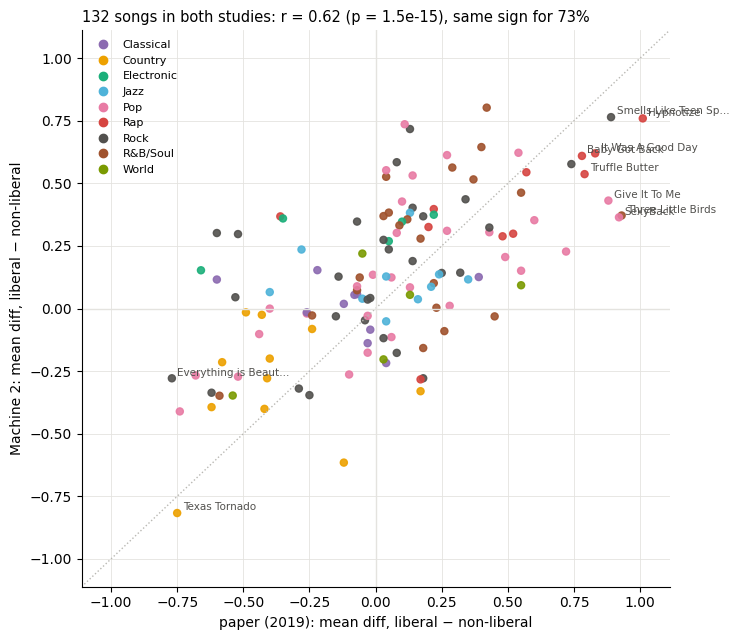

In [10]:
paper = pd.read_csv(PAPER_CSV).dropna(subset=['machine2_music_id'])
paper['machine2_music_id'] = paper.machine2_music_id.astype(int)
paper = paper.join(songs[['mean_diff', 'genre']], on='machine2_music_id').rename(columns={'mean_diff': 'machine2_mean_diff'})
r_paper, p_paper = st.pearsonr(paper.paper_mean_diff, paper.machine2_mean_diff)
sign_agree = (np.sign(paper.paper_mean_diff) == np.sign(paper.machine2_mean_diff)).mean()

fig, a = plt.subplots(figsize=(7.5, 6.5))
a.scatter(paper.paper_mean_diff, paper.machine2_mean_diff, c=paper.genre.map(GENRE_COLORS), s=26, alpha=0.9)
lim = np.abs(paper[['paper_mean_diff', 'machine2_mean_diff']].to_numpy()).max() * 1.1
a.plot([-lim, lim], [-lim, lim], ls=':', color=MUTED, lw=1)
a.axhline(0, color=GRID, lw=1); a.axvline(0, color=GRID, lw=1)
for _, r in paper.loc[paper.paper_mean_diff.abs().nlargest(10).index].iterrows():
    a.annotate(short(r.machine2_title, 20), (r.paper_mean_diff, r.machine2_mean_diff), fontsize=7.5, color=INK2,
               xytext=(4, 2), textcoords='offset points')
a.legend([plt.Line2D([], [], ls='', marker='o', color=c) for c in GENRE_COLORS.values()], GENRE_COLORS.keys(),
         frameon=False, fontsize=8, loc='upper left')
a.set_xlim(-lim, lim); a.set_ylim(-lim, lim)
a.set_xlabel('paper (2019): mean diff, liberal − non-liberal'); a.set_ylabel('Machine 2: mean diff, liberal − non-liberal')
a.set_title(f"{len(paper)} songs in both studies: r = {r_paper:.2f} (p = {p_paper:.1e}), same sign for {sign_agree:.0%}",
            loc='left', fontsize=10.5)
style(a, 'both'); plt.tight_layout(); plt.show()

## 4. Reclassification, exactly as in the paper (Fig 6)
* **Musical Ideology Index** of person *i* = Σ over clips of (rating − 4) × mean diff of the clip.
  Centring at 4 ("Indifferent") only matters for the few unrated clips (they add 0); with every clip rated, any
  constant shift moves all indices by the same amount and the cutoff absorbs it.
* Everyone above the cutoff is called liberal; the cutoff with the highest accuracy is picked.
* Mean diffs and cutoff are computed on the **whole sample** and the same people are then classified.

The index scale differs from the paper's (320 clips instead of ~190 per person), so only accuracies are comparable.

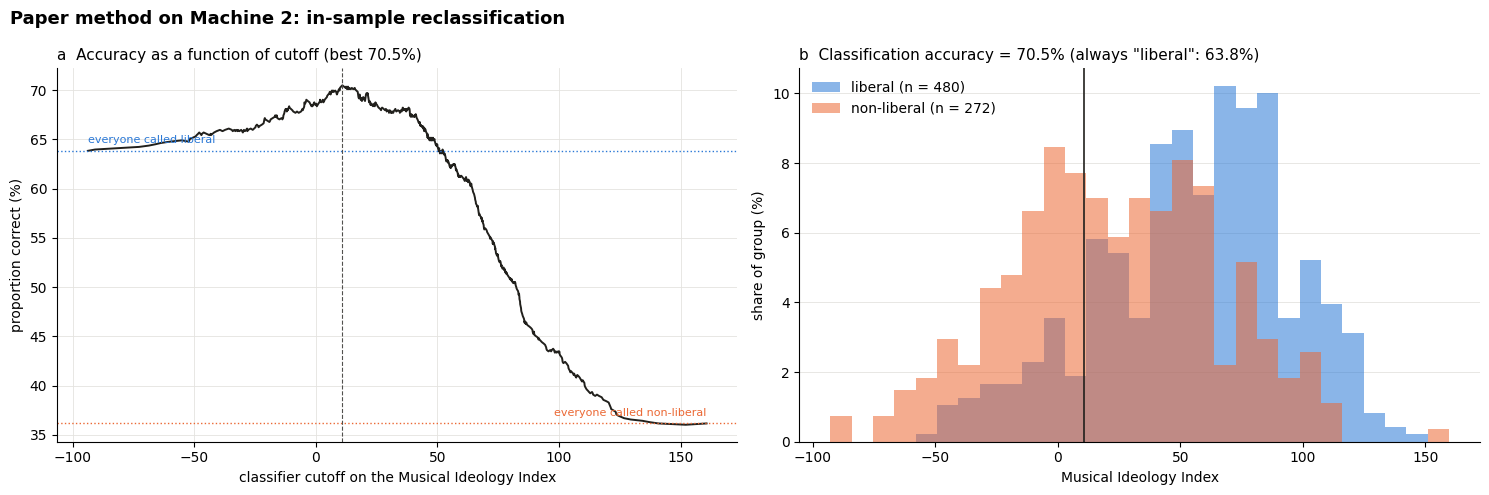

in-sample accuracy 0.705 (paper 0.715) | majority baseline 0.638 (paper 0.601) | gain +6.6 pts (paper +11.4)
balanced accuracy 0.643 | AUC of the index 0.716 | called liberal: 76.3% of people


predicted,liberal,non-liberal
true,,
liberal,416,64
non-liberal,158,114


In [11]:
md, index, cutoff, acc_in = reclassify_in_sample(Rf, M, U, yv)
base = max(yv.mean(), 1 - yv.mean())
auc_in = roc_auc_score(yv, index)
pred_in = (index > cutoff).astype(int)

cuts, accs = accuracy_by_cutoff(index, yv)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5))
a1.plot(cuts, 100 * accs, color=INK, lw=1.4)
a1.axhline(100 * yv.mean(), ls=':', color=BLUE, lw=1); a1.axhline(100 * (1 - yv.mean()), ls=':', color=ORANGE, lw=1)
a1.text(cuts[0], 100 * yv.mean() + 0.8, 'everyone called liberal', fontsize=8, color=BLUE)
a1.text(cuts[-1], 100 * (1 - yv.mean()) + 0.8, 'everyone called non-liberal', fontsize=8, color=ORANGE, ha='right')
a1.axvline(cutoff, color=INK2, lw=0.8, ls='--')
a1.set_xlabel('classifier cutoff on the Musical Ideology Index'); a1.set_ylabel('proportion correct (%)')
a1.set_title(f'a  Accuracy as a function of cutoff (best {acc_in:.1%})', loc='left', fontsize=11); style(a1, 'both')
bins = np.linspace(index.min(), index.max(), 30)
for d, c, lab in [(index[yv == 1], BLUE, 'liberal'), (index[yv == 0], ORANGE, 'non-liberal')]:
    a2.hist(d, bins=bins, weights=np.full(len(d), 100 / len(d)), color=c, alpha=0.55, label=f"{lab} (n = {len(d)})")
a2.axvline(cutoff, color=INK, lw=1.2)
a2.set_xlabel('Musical Ideology Index'); a2.set_ylabel('share of group (%)')
a2.set_title(f'b  Classification accuracy = {acc_in:.1%} (always "liberal": {base:.1%})', loc='left', fontsize=11)
a2.legend(frameon=False); style(a2)
fig.suptitle('Paper method on Machine 2: in-sample reclassification', x=0.01, ha='left', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

print(f"in-sample accuracy {acc_in:.3f} (paper 0.715) | majority baseline {base:.3f} (paper 0.601) | "
      f"gain {100 * (acc_in - base):+.1f} pts (paper +11.4)")
print(f"balanced accuracy {balanced_accuracy_score(yv, pred_in):.3f} | AUC of the index {auc_in:.3f} | "
      f"called liberal: {pred_in.mean():.1%} of people")
pd.crosstab(pd.Series(yv, name='true').map({1: 'liberal', 0: 'non-liberal'}),
            pd.Series(pred_in, name='predicted').map({1: 'liberal', 0: 'non-liberal'}))

## 5. How much of the accuracy is real?
Two checks the paper did not run:
1. **Shuffled labels.** Ideology labels are permuted `N_PERM` times and the whole in-sample procedure (mean diffs + best
   cutoff) is rerun. This shows what accuracy the method produces when music has nothing to do with ideology: fitting
   320 weights and a cutoff on the people being scored inflates accuracy above the majority baseline by itself.
2. **Held-out participants.** Repeated stratified 5-fold cross-validation: mean diffs and cutoff are estimated on 4/5
   of the people and the remaining 1/5 is classified (`CV_REPEATS` different splits). AUC (chance = 0.5) is reported
   alongside accuracy because the best-accuracy cutoff calls almost everyone "liberal" when the signal is weak. Its
   p-value comes from the same cross-validation rerun on each shuffled labelling (one split each).

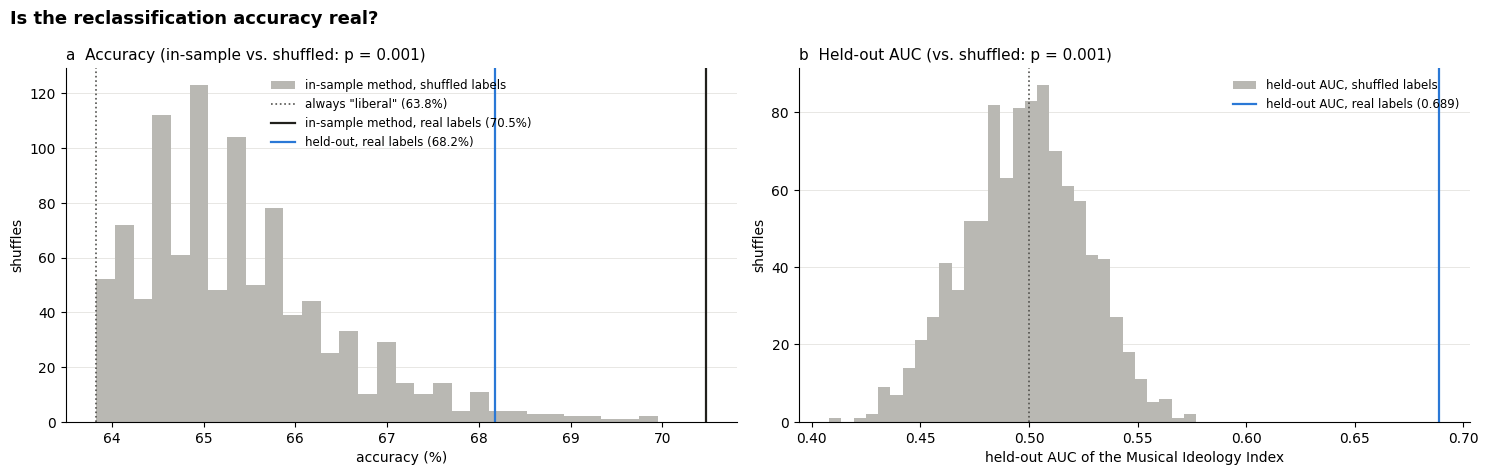

held-out over 20 repeats: accuracy 0.670–0.691, AUC 0.677–0.696; 76.5% of people called liberal on average


,accuracy,auc,p_vs_shuffled,balanced_accuracy
estimate,,,,
"always ""liberal"" (majority baseline)",0.638,NaN,NaN,NaN
paper method: in-sample reclassification,0.705,0.716,0.001,NaN
"same method, shuffled labels: mean",0.654,NaN,NaN,NaN
"same method, shuffled labels: 95th percentile",0.676,NaN,NaN,NaN
held-out (5-fold × 20 repeats): mean,0.682,0.689,0.001,0.617


In [12]:
def validate(Rf, M, U, y, perms, seed=SEED):
    null_in = np.array([reclassify_in_sample(Rf, M, U, yp)[3] for yp in perms])
    cv = []
    for r in range(CV_REPEATS):
        score, pred = cv_reclassify(Rf, M, U, y, seed + r)
        cv.append(dict(accuracy=(pred == y).mean(), balanced_accuracy=balanced_accuracy_score(y, pred),
                       auc=roc_auc_score(y, score), called_liberal=pred.mean()))
    null_cv_auc = np.array([roc_auc_score(yp, cv_reclassify(Rf, M, U, yp, seed + i)[0]) for i, yp in enumerate(perms)])
    return null_in, pd.DataFrame(cv), null_cv_auc


null_in, cv, null_cv_auc = validate(Rf, M, U, yv, PERMS)
p_in, p_cv = p_perm(null_in, acc_in), p_perm(null_cv_auc, cv.auc.mean())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.8))
a1.hist(100 * null_in, bins=30, color=MUTED, label='in-sample method, shuffled labels')
a1.axvline(100 * base, ls=':', color=INK2, lw=1.2, label=f'always "liberal" ({base:.1%})')
a1.axvline(100 * acc_in, color=INK, lw=1.6, label=f'in-sample method, real labels ({acc_in:.1%})')
a1.axvline(100 * cv.accuracy.mean(), color=BLUE, lw=1.6, label=f'held-out, real labels ({cv.accuracy.mean():.1%})')
a1.set_xlabel('accuracy (%)'); a1.set_ylabel('shuffles')
a1.set_title(f'a  Accuracy (in-sample vs. shuffled: p = {p_in:.3f})', loc='left', fontsize=11)
a1.legend(frameon=False, fontsize=8.5); style(a1)
a2.hist(null_cv_auc, bins=30, color=MUTED, label='held-out AUC, shuffled labels')
a2.axvline(cv.auc.mean(), color=BLUE, lw=1.6, label=f'held-out AUC, real labels ({cv.auc.mean():.3f})')
a2.axvline(0.5, ls=':', color=INK2, lw=1.2)
a2.set_xlabel('held-out AUC of the Musical Ideology Index'); a2.set_ylabel('shuffles')
a2.set_title(f'b  Held-out AUC (vs. shuffled: p = {p_cv:.3f})', loc='left', fontsize=11)
a2.legend(frameon=False, fontsize=8.5); style(a2)
fig.suptitle('Is the reclassification accuracy real?', x=0.01, ha='left', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

validation = pd.DataFrame([
    dict(estimate='always "liberal" (majority baseline)', accuracy=base),
    dict(estimate='paper method: in-sample reclassification', accuracy=acc_in, auc=auc_in, p_vs_shuffled=p_in),
    dict(estimate='  same method, shuffled labels: mean', accuracy=null_in.mean()),
    dict(estimate='  same method, shuffled labels: 95th percentile', accuracy=np.quantile(null_in, .95)),
    dict(estimate=f'held-out ({CV_SPLITS}-fold × {CV_REPEATS} repeats): mean', accuracy=cv.accuracy.mean(),
         balanced_accuracy=cv.balanced_accuracy.mean(), auc=cv.auc.mean(), p_vs_shuffled=p_cv),
]).set_index('estimate')
print(f"held-out over {CV_REPEATS} repeats: accuracy {cv.accuracy.min():.3f}–{cv.accuracy.max():.3f}, "
      f"AUC {cv.auc.min():.3f}–{cv.auc.max():.3f}; {cv.called_liberal.mean():.1%} of people called liberal on average")
validation.round(3)

## 6. Sensitivity to the liberal / non-liberal grouping
Machine 2's ideology answers do not map one-to-one onto the paper's. Same pipeline (sections 4–5) with four groupings:
* **main:** Liberal + Progressive + Socialist vs. everyone else (as above)
* **literal:** only "Liberal" vs. everyone else (progressives and socialists counted as non-liberal)
* **without "I don't care":** main grouping, but only people who named an ideology
* **left vs. right:** Liberal + Progressive + Socialist vs. Conservative + Libertarian + Alt-Right (very unbalanced)

Accuracy has to be read against each grouping's own majority baseline; AUC is comparable across groupings.

In [13]:
GROUPINGS = {
    'main: left vs. everyone else': (LIBERAL, None),
    'literal: "Liberal" vs. everyone else': (['Liberal'], None),
    'left vs. everyone else, without "I don\'t care"': (LIBERAL, ['Moderate', 'Conservative', 'Libertarian', 'Alt-Right']),
    'left vs. right': (LIBERAL, ['Conservative', 'Libertarian', 'Alt-Right']),
}
rows = []
for name, (pos, neg) in GROUPINGS.items():
    keep = (ideo.isin(pos + neg) if neg else ideo.notna()).to_numpy()
    yg = ideo[keep].isin(pos).astype(int).to_numpy()
    Rf_g, M_g, U_g = arrays(R[keep])
    *_, acc_g = reclassify_in_sample(Rf_g, M_g, U_g, yg)
    null_g, cv_g, null_auc_g = validate(Rf_g, M_g, U_g, yg, make_perms(yg))
    rows.append({'grouping': name, 'n': len(yg), 'n_liberal': int(yg.sum()), 'majority_baseline': max(yg.mean(), 1 - yg.mean()),
                 'in_sample_accuracy': acc_g, 'shuffled_in_sample_95th': np.quantile(null_g, .95),
                 'p_in_sample': p_perm(null_g, acc_g), 'heldout_accuracy': cv_g.accuracy.mean(),
                 'heldout_balanced_accuracy': cv_g.balanced_accuracy.mean(), 'heldout_auc': cv_g.auc.mean(),
                 'p_heldout_auc': p_perm(null_auc_g, cv_g.auc.mean())})
sensitivity = pd.DataFrame(rows).set_index('grouping')
sensitivity.round(3)

,n,n_liberal,majority_baseline,in_sample_accuracy,shuffled_in_sample_95th,p_in_sample,heldout_accuracy,heldout_balanced_accuracy,heldout_auc,p_heldout_auc
grouping,,,,,,,,,,
main: left vs. everyone else,752,480,0.638,0.705,0.676,0.001,0.682,0.617,0.689,0.001
"literal: ""Liberal"" vs. everyone else",752,333,0.557,0.625,0.629,0.067,0.578,0.566,0.615,0.001
"left vs. everyone else, without ""I don't care""",623,480,0.770,0.783,0.785,0.092,0.764,0.503,0.629,0.001
left vs. right,521,480,0.921,0.921,0.931,1.000,0.919,0.499,0.610,0.018


## 7. Summary: paper vs. Machine 2

In [14]:
n_click = flow.dropped.iloc[-1]
n_before_click = flow.participants.iloc[-2]
summary = pd.DataFrame({
    'paper (Myers 2019)': {
        'participants analysed': '576',
        'liberal / non-liberal': '346 / 230 (60.1 % liberal)',
        'click-through exclusions': '49 of 625 (7.8 %)',
        'songs': '260 (random subset per person)',
        'song-level agreement with the paper': '—',
        'in-sample reclassification accuracy': '71.5 %',
        'majority baseline': '60.1 %',
        'gain over baseline': '+11.4 pts',
        'shuffled-label in-sample accuracy (95th pct)': 'not reported',
        'held-out accuracy': 'not reported',
        'held-out AUC': 'not reported'},
    'Machine 2': {
        'participants analysed': f'{len(yv)}',
        'liberal / non-liberal': f'{yv.sum()} / {(1 - yv).sum()} ({yv.mean():.1%} liberal)',
        'click-through exclusions': f'{n_click} of {n_before_click} ({n_click / n_before_click:.1%})',
        'songs': '320 (all rated by everyone)',
        'song-level agreement with the paper': f'r = {r_paper:.2f} over {len(paper)} shared songs ({sign_agree:.0%} same sign)',
        'in-sample reclassification accuracy': f'{acc_in:.1%}',
        'majority baseline': f'{base:.1%}',
        'gain over baseline': f'{100 * (acc_in - base):+.1f} pts',
        'shuffled-label in-sample accuracy (95th pct)': f'{np.quantile(null_in, .95):.1%} (p = {p_in:.3f})',
        'held-out accuracy': f'{cv.accuracy.mean():.1%}',
        'held-out AUC': f'{cv.auc.mean():.3f} (p = {p_cv:.3f})'},
})
songs.to_csv("../results/music_politics/music_politics_song_differences.csv")
sensitivity.to_csv("../results/music_politics/music_politics_reclassification.csv")
print("saved music_politics_song_differences.csv and music_politics_reclassification.csv")
summary

saved music_politics_song_differences.csv and music_politics_reclassification.csv


,paper (Myers 2019),Machine 2
participants analysed,576,752
liberal / non-liberal,346 / 230 (60.1 % liberal),480 / 272 (63.8% liberal)
click-through exclusions,49 of 625 (7.8 %),17 of 769 (2.2%)
songs,260 (random subset per person),320 (all rated by everyone)
song-level agreement with the paper,—,r = 0.62 over 132 shared songs (73% same sign)
in-sample reclassification accuracy,71.5 %,70.5%
majority baseline,60.1 %,63.8%
gain over baseline,+11.4 pts,+6.6 pts
shuffled-label in-sample accuracy (95th pct),not reported,67.6% (p = 0.001)
held-out accuracy,not reported,68.2%
